# Lab 2.2 Classification (with neurons)

**📎 From the slide to the code** · **Lab slides**, slide 12 *BERT*

| In the slide | In the code |
|---|---|
| BERT: the same word gets a different vector in each context | `BertModel.from_pretrained('bert-base-uncased')` |
| bert-base: 12 layers, 768-dim vectors, 30,522 sub-words | `config`: `num_hidden_layers`, `hidden_size`, `vocab_size` |

BERT (Bidirectional Encoder Representations from Transformers) is a language representation model developed by Google in 2018. It is pre-trained on a large amount of text, and then it can be adapted (**fine-tuned**) to a specific task, such as classifying reviews.

**The key idea: one vector per word *in its context*.** In Word2Vec (Lab 1) a word has **one** vector, whatever the sentence. BERT reads all the words of the sentence together, in both directions, so the vector of a word **depends on the sentence**. For example, the vectors of *bank* given by `bert-base-uncased` in three sentences:

| two sentences | cosine similarity of the two *bank* vectors |
|---|---|
| *we sat on the bank of the river* / *i deposited money at the bank* | 0.30 |
| *we sat on the bank of the river* / *the bank approved my loan* | 0.44 |
| *the bank approved my loan* / *i deposited money at the bank* | 0.54 |

The two *money* meanings are the closest; the *river* meaning is the farthest.

**What we do in this lab:**
1. the **tokenizer** turns the text into ids (numbers);
2. **BERT** turns each id into a vector of 768 numbers, which depends on the context;
3. with **fine-tuning**, a small classifier on top of BERT learns to predict the class of a text (here the stars of a review).

> **Use a GPU** in Colab (*Runtime → Change runtime type → GPU*): the fine-tuning sections below are very slow on CPU.

In [1]:
from transformers import BertTokenizer, BertModel, BertConfig
from transformers import logging

# Show only errors: hide the long "LOAD REPORT" printed every time a model is loaded
logging.set_verbosity_error()

In [ ]:
# Download the BERT tokenizer: it splits the text into tokens and turns them into ids
bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

# Download the pre-trained BERT model
bert_model = BertModel.from_pretrained('bert-base-uncased')

You could also use the config class to initialize the network. Mainly when you don't want to use a pretrained model, but only a standard set of hyper parameters.

In [ ]:
# The settings of bert-base: number of layers, size of the vectors, size of the vocabulary, ...
config = BertConfig.from_pretrained("bert-base-uncased")

# To build a BERT with these settings but random weights (not pre-trained):
# bert_model = BertModel.from_config(config)

# Display the settings
config

BertConfig {
  "add_cross_attention": false,
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "eos_token_id": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "tie_word_embeddings": true,
  "transformers_version": "5.22.2",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}

In [ ]:
# A sentence with a rare word (pytorch)
sentence = 'Just an example, random words: pytorch vs tensorflow'

# Split it into BERT tokens
tokens = bert_tokenizer.tokenize(sentence)
print(tokens)

['just', 'an', 'example', ',', 'random', 'words', ':', 'p', '##yt', '##or', '##ch', 'vs', 'tensor', '##flow']


BERT tokens are neither words, nor characters, nor lemmas or stems: they are **sub-words** (WordPiece). Frequent words stay whole (`just`, `example`), rare words are split into pieces: `pytorch` → `p`, `##yt`, `##or`, `##ch` (`##` = this piece continues the previous one).

**To learn more about sub-word tokenizers** (Hugging Face LLM course):
- [WordPiece tokenization](https://huggingface.co/learn/llm-course/chapter6/6): the algorithm used by **BERT**. It builds the vocabulary step by step, starting from single characters and merging pairs of pieces: it prefers the pairs that appear together more often than expected from how frequent each piece is alone. *Note: Google never open-sourced its training algorithm of WordPiece, so this page is the Hugging Face team's best guess from the published papers: it may not be 100% accurate.*
- [Byte-Pair Encoding (BPE) tokenization](https://huggingface.co/learn/llm-course/chapter6/5): a similar algorithm, used by **GPT** models. It also starts from single characters, and at each step merges the **most frequent** pair of pieces.

## Sentence tokenizer encoding and decoding

**📎 From the slide to the code** · **Lab slides**, slide 12 *BERT*

| In the slide | In the code |
|---|---|
| [CLS] at the start, [SEP] at the end | `add_special_tokens=True` |
| [PAD] up to max_length | `max_length=30, padding='max_length'` |
| attention_mask: 1 = real token, 0 = padding | `return_attention_mask=True` |
| Back to text | `bert_tokenizer.decode(...)` |
| encode_plus (old name) | now call the tokenizer directly: `bert_tokenizer(sentence, ...)` |

What these terms mean:
- **[CLS]** (*classification*): a special token added at the start. Its vector is often used as the vector of the whole sentence.
- **[SEP]** (*separator*): a special token added at the end of the sentence (or between two sentences).
- **[PAD]** (*padding*): a filling token. The sentences of a batch must all have the same length, so the short ones are filled with [PAD] up to `max_length`.
- **attention_mask**: one number per position, 1 = real token, 0 = [PAD]. It tells the model to ignore the padding.
- **decode**: the opposite of encoding, from the ids back to text.
- **encode_plus**: the old name of the encoding function; in recent versions we call the tokenizer directly.

**To pass the sentences to the model we turn them into integers (calling the tokenizer on the sentence), and to read the output we turn the integers back into tokens (`decode`).**

In [ ]:
# Encode the sentence: the id of each token, + [CLS] and [SEP], padded with [PAD] up to 30 positions
ids_encode = bert_tokenizer(
    sentence,
    # Add [CLS] at the start and [SEP] at the end
    add_special_tokens = True,
    # Every sentence becomes exactly 30 positions long
    max_length = 30,
    # Also return the mask: 1 = real token, 0 = padding
    return_attention_mask = True,
    # Fill short sentences with [PAD] ...
    padding="max_length",
    # ... and cut long ones
    truncation=True
)

# Display the result: three lists of 30 numbers
print("encode:",ids_encode)

encode: {'input_ids': [101, 2074, 2019, 2742, 1010, 6721, 2616, 1024, 1052, 22123, 2953, 2818, 5443, 23435, 12314, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


In [ ]:
# Back from ids to text
print("decode:", bert_tokenizer.decode(ids_encode['input_ids']))

decode: [CLS] just an example, random words : pytorch vs tensorflow [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


**Why so many `[PAD]`?** `decode` turns **all** the 30 ids back into text, also the special ones: `[CLS]` at the start, `[SEP]` at the end, and the 14 `[PAD]` added to reach `max_length=30`. To get only the text of the sentence:

```python
bert_tokenizer.decode(ids_encode['input_ids'], skip_special_tokens=True)
# 'just an example, random words : pytorch vs tensorflow'
```

(The text is lowercase because this BERT is *uncased*.)

In [ ]:
# The token of id 101: a special token
bert_tokenizer.convert_ids_to_tokens(101)

'[CLS]'

## Exercise 2.1: special tokens, padding and truncation

Use `sentence` and the output of the cells above.

1. The sentence has 14 tokens: why does `input_ids` start with 16 values different from 0? Which ids are `[CLS]`, `[SEP]` and `[PAD]`?
2. What is the `attention_mask` for, and why does it end with 0s?
3. Encode the same sentence with `max_length=10`. Which tokens are lost? Is `[SEP]` still there?

*Hint: `bert_tokenizer.convert_ids_to_tokens(list_of_ids)` turns a list of ids into tokens.*

In [ ]:
# Your code here

### How to think about it

**The idea, without code**

- A neural model reads numbers, not words: the text is cut into pieces (sub-words) and each piece becomes a number.
- Some markers are added to the sequence (start, end), and all the sequences of a batch must have the same length: short ones are filled, long ones are cut.
- The model must know which positions are real text and which are only filling: a mask tells it.

**From the idea to the code**

1. **What do we want?** To explain the numbers in `input_ids` and `attention_mask`, and what truncation does.
2. **What do we have?** The encoded sentence (`ids_encode`), its 14 tokens, and the tokenizer.
3. **How do we get there?**

   **Step 1: Make the ids readable.** Ids are numbers: turn them back into tokens to see what each one is.

   *Code:* `bert_tokenizer.convert_ids_to_tokens(ids_encode['input_ids'])`

   **Step 2: Count the positions.** The ids different from 0 are the 14 tokens of the sentence, plus one special token added at the start and one at the end. All the other positions, up to the maximum length of 30, are filling tokens.

   **Step 3: Read the mask.** Put `attention_mask` under the tokens: there is one number per position. It is 1 under each real token (`[CLS]`, the 14 tokens of the sentence, `[SEP]`) and 0 under each `[PAD]`. The 0s are at the end because the `[PAD]` are at the end: this is how the model knows which positions to ignore.

   **Step 4: Try truncation.** Encode the sentence again with a maximum length of 10 and turn the ids into tokens to see what is left.

   *Code:* `bert_tokenizer(sentence, max_length=10, padding='max_length', truncation=True)`

4. **How do we check it?** The count must add up: 14 + 2 + 14 filling tokens = 30, the maximum length. With a maximum length of 10: 2 special tokens and 8 tokens of the sentence.


**Watch out: the limit is in tokens, not words: *pytorch* alone takes 4 tokens.**

### Solution 2.1

In [ ]:
# Step 1: Make the ids readable: [CLS] + 14 tokens + [SEP], then [PAD]
print(bert_tokenizer.convert_ids_to_tokens(ids_encode['input_ids']))

# Step 2: The ids of the special tokens
print('[CLS], [SEP], [PAD] =', bert_tokenizer.convert_tokens_to_ids(['[CLS]', '[SEP]', '[PAD]']))

['[CLS]', 'just', 'an', 'example', ',', 'random', 'words', ':', 'p', '##yt', '##or', '##ch', 'vs', 'tensor', '##flow', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
[CLS], [SEP], [PAD] = [101, 102, 0]


In [ ]:
# Step 4: Try truncation: only 10 positions
short = bert_tokenizer(sentence, add_special_tokens=True, max_length=10,
                                   padding="max_length", truncation=True)

# Display the ids, then the same ids as tokens
print(short['input_ids'])
print(bert_tokenizer.convert_ids_to_tokens(short['input_ids']))

[101, 2074, 2019, 2742, 1010, 6721, 2616, 1024, 1052, 102]
['[CLS]', 'just', 'an', 'example', ',', 'random', 'words', ':', 'p', '[SEP]']


**Answers:**

1. 16 = 14 tokens + `[CLS]` (id **101**) at the start + `[SEP]` (id **102**) at the end. The other 14 positions, up to `max_length=30`, are `[PAD]` (id **0**).
2. `attention_mask` is 1 for the 16 real tokens and 0 for the padding: the model must not look at the `[PAD]` positions. Padding is needed because a batch of sentences must have the same length.
3. With `max_length=10` only 8 tokens of the sentence fit: `[CLS] just an example , random words : p [SEP]` (ids `[101, 2074, 2019, 2742, 1010, 6721, 2616, 1024, 1052, 102]`). The rest (`##yt ##or ##ch vs tensor ##flow`) is lost, even in the middle of the word `pytorch`; `[SEP]` is still added at the end.

We can use BERT to compare the meaning of sentences: one vector per sentence, then the cosine similarity (as in Lab 1).

**The problem:** BERT gives a vector for **each token**, not one for the whole sentence. For *"I enjoy walking in the park."* BERT gives 9 vectors of 768 numbers, one for each token:

`[CLS]` · `i` · `enjoy` · `walking` · `in` · `the` · `park` · `.` · `[SEP]`

In the code these vectors are in `outputs.last_hidden_state`, a table with 3 dimensions: (number of sentences, number of tokens, 768) = (1, 9, 768).

**Solution 1, the `[CLS]` vector:** keep only the vector of the first token, `[CLS]`. In the code, `last_hidden_state[:, 0, :]` means: all the sentences (`:`), the token in position 0 (`[CLS]`), all the 768 numbers (`:`).

**What the next cell does:** it takes 3 sentences. Sentences 1 and 2 have a similar meaning (a walk in a park, a stroll in a garden), sentence 3 is different (traffic). For each sentence it computes the `[CLS]` vector, then the cosine similarity of each pair. We expect 1–2 high, 1–3 and 2–3 lower.

In [ ]:
import torch
import torch.nn.functional as F

# Three sentences: 1 and 2 have a similar meaning, 3 is different
text1 = "I enjoy walking in the park."
text2 = "I love going for a stroll in the garden."
text3 = "I dislike being stuck in traffic."

# The [CLS] vector of a sentence
def get_embedding(text, tokenizer, model):
    # 1. Turn the text into ids (return_tensors="pt": as PyTorch tensors)
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
    # 2. Run BERT on the ids; no training here, so no gradients (faster, less memory)
    with torch.no_grad():
        # **inputs passes input_ids, attention_mask, ... as named arguments
        outputs = model(**inputs)
    # 3. Keep only the vector of [CLS]: all the sentences, position 0, all the 768 numbers
    cls_embedding = outputs.last_hidden_state[:, 0, :]
    return cls_embedding

# The [CLS] vector of each sentence
embedding1 = get_embedding(text1, bert_tokenizer, bert_model)
embedding2 = get_embedding(text2, bert_tokenizer, bert_model)
embedding3 = get_embedding(text3, bert_tokenizer, bert_model)

# Cosine similarity of each pair of sentences (.item() turns a tensor with one number into a Python number)
similarity_1_2 = F.cosine_similarity(embedding1, embedding2).item()
similarity_1_3 = F.cosine_similarity(embedding1, embedding3).item()
similarity_2_3 = F.cosine_similarity(embedding2, embedding3).item()

# Print results
print(f"Similarity between Text1 and Text2: {similarity_1_2:.4f}")
print(f"Similarity between Text1 and Text3: {similarity_1_3:.4f}")
print(f"Similarity between Text2 and Text3: {similarity_2_3:.4f}")

Similarity between Text1 and Text2: 0.9593
Similarity between Text1 and Text3: 0.9355
Similarity between Text2 and Text3: 0.9364


**Careful:** the three similarities are all very high, even for the sentence about traffic. The `[CLS]` vector of a BERT that was **not fine-tuned** is not a good sentence vector: it was trained for next-sentence prediction, not for similarity.

**Solution 2, mean pooling:** the average of the vectors of **all the real tokens** (the `[PAD]` are excluded). The mask removes the padding: multiply each token vector by its mask value (1 or 0), add them up, and divide by the number of real tokens. For example, with 3 positions and vectors of 2 numbers:
- vectors `[1, 2]`, `[3, 4]`, `[9, 9]` (the last one is a `[PAD]`), mask `[1, 1, 0]`;
- after the multiplication: `[1, 2]`, `[3, 4]`, `[0, 0]`; sum `[4, 6]`;
- divided by 2 real tokens: `[2, 3]`.

The next cell computes the same similarities with mean pooling: compare the numbers! (Models trained for similarity, like Sentence-BERT, do even better.)

In [ ]:
# The mean pooling vector of a sentence: the average of the vectors of its real tokens
def get_mean_embedding(text, tokenizer, model):
    # 1. Turn the text into ids, and run BERT without gradients
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
    # 2. The mask (1 = real token, 0 = padding), from shape (1, tokens) to (1, tokens, 1)
    # so that it can multiply the vectors of shape (1, tokens, 768)
    mask = inputs["attention_mask"].unsqueeze(-1)
    # 3. Multiply (the padding vectors become 0), then sum over the tokens (dim=1)
    summed = (outputs.last_hidden_state * mask).sum(dim=1)
    # 4. Divide by the number of real tokens: the average
    return summed / mask.sum(dim=1)

# The mean pooling vector of each sentence
mean1, mean2, mean3 = (get_mean_embedding(t, bert_tokenizer, bert_model) for t in (text1, text2, text3))

# Cosine similarity of each pair, as above
print(f"Mean pooling - Text1 vs Text2: {F.cosine_similarity(mean1, mean2).item():.4f}")
print(f"Mean pooling - Text1 vs Text3: {F.cosine_similarity(mean1, mean3).item():.4f}")
print(f"Mean pooling - Text2 vs Text3: {F.cosine_similarity(mean2, mean3).item():.4f}")

Mean pooling - Text1 vs Text2: 0.8909
Mean pooling - Text1 vs Text3: 0.7481
Mean pooling - Text2 vs Text3: 0.6723


# Fine-tuning

**📎 From the slide to the code** · **Lab slides**, slide 13 *Fine-tuning & PEFT*

| In the slide | In the code |
|---|---|
| Fine-tune on 1,000 Yelp reviews, 5 classes | `AutoModelForSequenceClassification.from_pretrained(..., num_labels=5)` |
| Full fine-tuning: 108,314,117 parameters | `print_trainable_parameters(model)` |
| Head only: 3,845 parameters | `requires_grad = False` for everything except `classifier.` |
| LoRA (r = 16): 593,669 parameters | `get_peft_model(model, LoraConfig(r=16, ...))` |

**Fine-tuning** is a machine learning process where a pre-trained model is adapted to a specific task or domain by further training it on a smaller, task-specific dataset. This approach *leverages the knowledge the model has already learned during its initial training on a large and general-purpose dataset*, making it a powerful method for solving specialized problems efficiently.

### Why Fine-Tuning is Important
- **Efficient Use of Resources:** Training a model from scratch requires massive datasets and extensive computational power. Fine-tuning eliminates the need for this by building upon a pre-trained model.

- **Domain Adaptation:** Pre-trained models may not perform optimally in niche areas (e.g., medical imaging or legal documents). Fine-tuning allows the model to specialize in these domains.

- **Improved Performance:** Fine-tuning aligns the pre-trained model's features with task-specific requirements, often leading to state-of-the-art results.

- **Transfer Learning:** Fine-tuning is a key component of transfer learning, enabling the use of a general-purpose model in a new, related task.


**What happens in practice.** BERT alone gives vectors, not classes. To classify, `AutoModelForSequenceClassification` adds on top of BERT one small layer, called the **head** (or *classifier*: here the two words mean the same thing). The head takes the 768 numbers of the `[CLS]` vector and computes 5 scores, one per star: the predicted star is the one with the highest score.

The head is new: its weights start random, so before training its predictions are random. (This is what the loading message says when it lists `classifier.weight` and `classifier.bias` as *MISSING*: they are not in the pre-trained BERT, they are created now.) Training on 1,000 reviews with their stars changes the weights so that the highest score becomes the right star.

We compare four ways to fine-tune the same BERT on the same reviews. They differ in **which weights are changed** by training:

| method | what is trained | trainable parameters |
|---|---|---|
| full | all of BERT + the head | 108,314,117 |
| head | only the head (BERT frozen) | 3,845 |
| LoRA (r = 16) | small extra matrices + the head | 593,669 |
| AdaLoRA | like LoRA, with a rank that changes per layer | 594,053 |

Fewer trainable parameters = faster and lighter training, but maybe lower accuracy: how much do we lose?

To get some extra speed, select a GPU. Be aware that there are usage limits, so use it strategically.

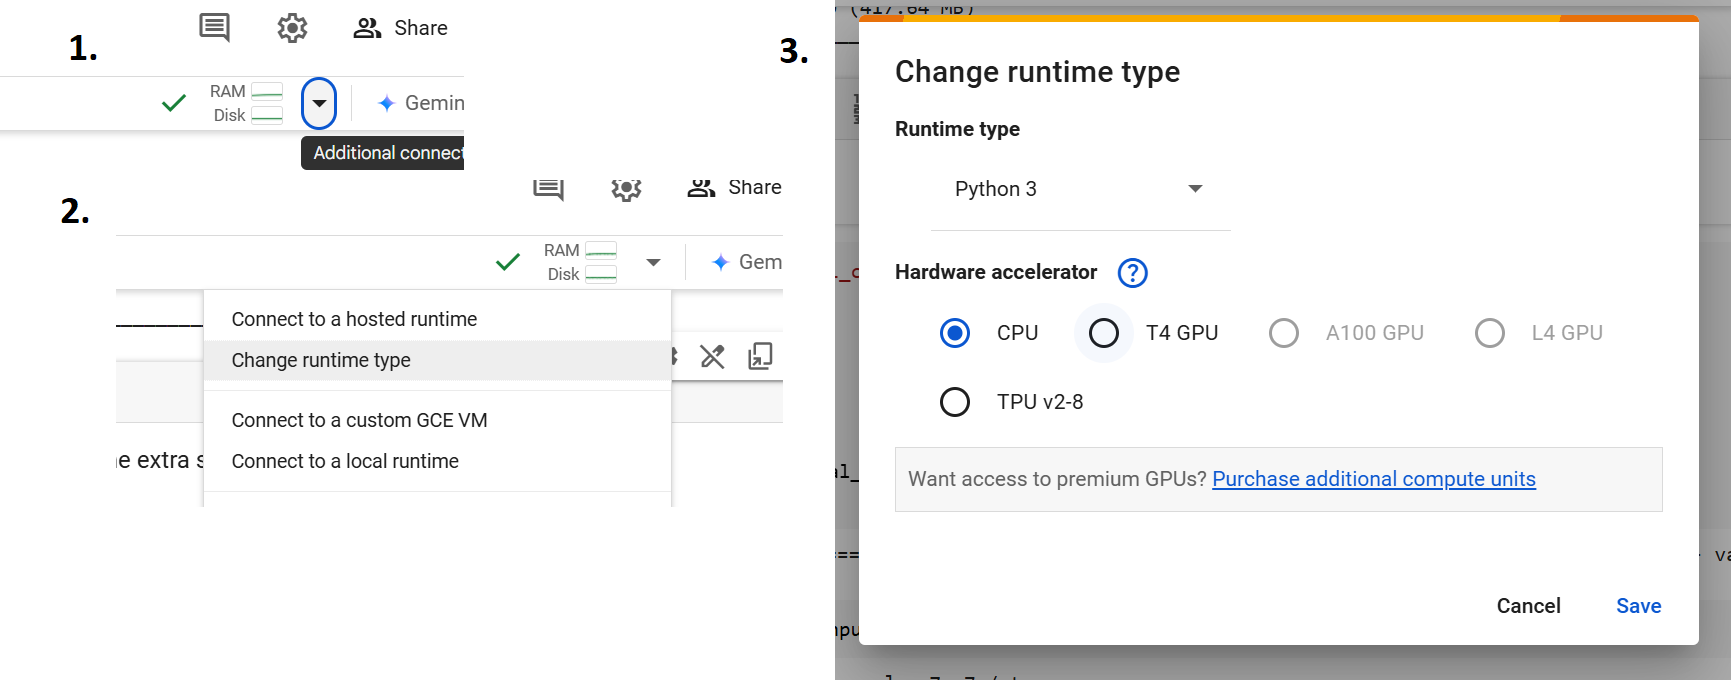


## PEFT

PEFT (Parameter-Efficient Fine-Tuning) trains only a small part of the parameters.

**LoRA.** Each layer of BERT multiplies its input by weight matrices W: for example the *query* and *value* matrices, 768 × 768 = 589,824 numbers each. Full fine-tuning changes all of W. LoRA **freezes** W and learns only a small correction, the product of two thin matrices B and A:
$$W' = W + \frac{\alpha}{r}\,B A \qquad B: 768 \times r, \quad A: r \times 768$$
- **r** (the *rank*) is the size of the small matrices: B has r columns and A has r rows. The smaller r, the fewer numbers to train.
- With r = 16: 768 × 16 + 16 × 768 = **24,576** numbers to train instead of 589,824 (about 4%).
- B·A is still a 768 × 768 matrix, but a "simple" one (rank at most r): this is often enough to adapt the model to a new task.
- At the start B = 0, so W' = W: training starts from the original BERT.
- `lora_alpha` ($\alpha$) sets how strong the correction is: here $\alpha / r$ = 32 / 16 = 2.

**AdaLoRA** uses the same idea, but does not give the same rank r to every matrix. During training it measures which matrices are most useful, and moves the rank there: here every matrix starts with r = 16, and at the end the average is r = 8.

We use the Hugging Face libraries: `transformers` (models), `datasets` (data), `peft` (LoRA, AdaLoRA), `evaluate` (metrics), on top of PyTorch.

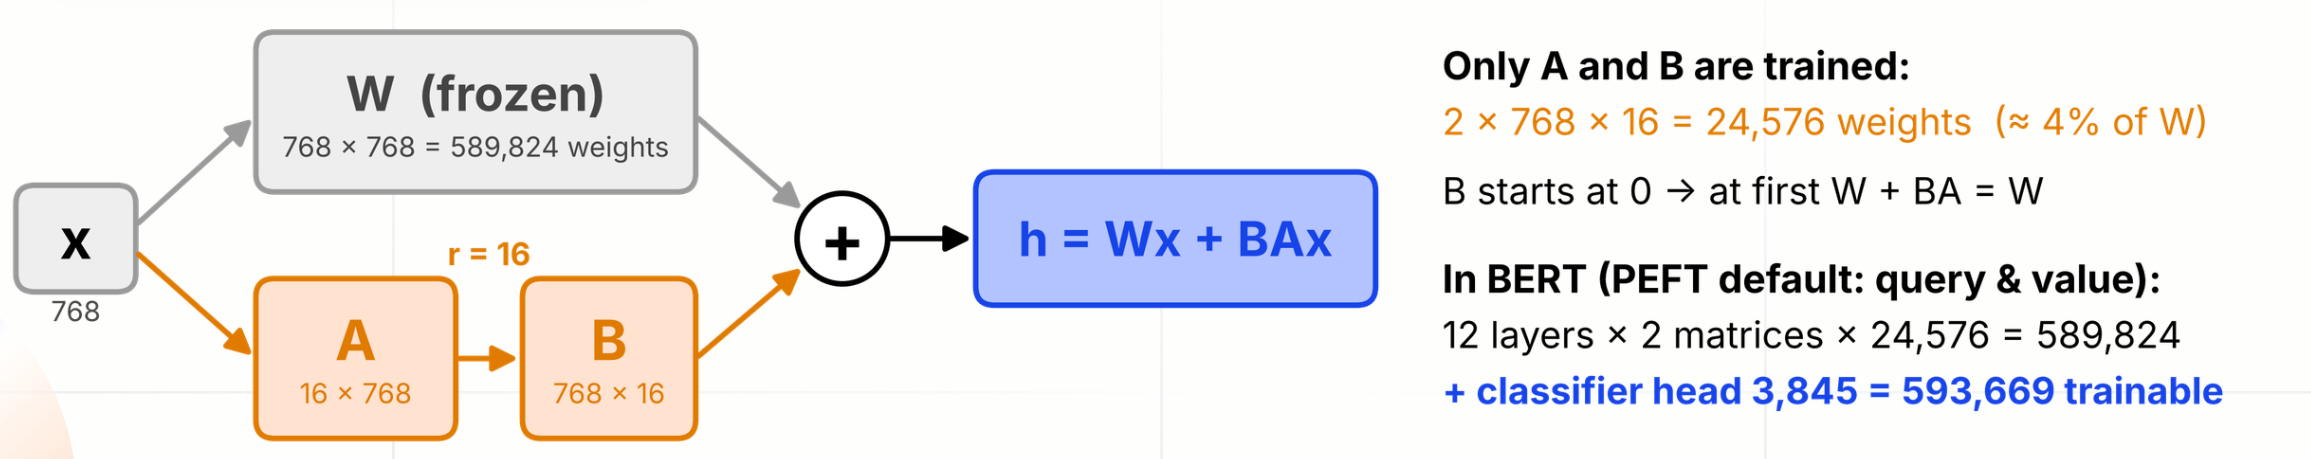

In [ ]:
!pip install peft datasets evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.9 MB/s eta 0:00:00


In [ ]:
import math
import numpy as np
import torch

import evaluate
from datasets import load_dataset
from peft import LoraConfig, AdaLoraConfig, get_peft_model
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, TrainerCallback)
from transformers import logging

# Show only errors: hide the long "LOAD REPORT" printed every time a model is loaded
logging.set_verbosity_error()

In [ ]:
# The same pre-trained BERT for the model and for the tokenizer (cased: it keeps capital letters)
model_name_or_path = "google-bert/bert-base-cased"
tokenizer_name_or_path = "google-bert/bert-base-cased"

In [ ]:
# Download the Yelp reviews: label 0-4 = 1-5 stars
dataset = load_dataset('Yelp/yelp_review_full')

# Display the splits and one review
print(dataset)
print(dataset["train"][100])

# The tokenizer of the same BERT
tokenizer = AutoTokenizer.from_pretrained(tokenizer_name_or_path)

# Tokenize a batch of reviews: each one becomes 512 positions (padded or cut)
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding='max_length',
        truncation=True
        )

# First select 1000 + 1000 reviews, then tokenize only those
# (tokenizing all 650,000 reviews and then keeping 1000 takes a long time and a lot of RAM)
# shuffle(seed=42): random order, always the same; select(range(1000)): the first 1000;
# batched=True: tokenize many reviews at once
small_train_dataset = dataset["train"].shuffle(seed=42).select(range(1000)).map(tokenize_function, batched=True)
small_eval_dataset = dataset["test"].shuffle(seed=42).select(range(1000)).map(tokenize_function, batched=True)

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 650000
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 50000
    })
})
{'label': 0, 'text': 'My expectations for McDonalds are t rarely high. But for one to still fail so spectacularly...that takes something special!\\nThe cashier took my friends\'s order, then promptly ignored me. I had to force myself in front of a cashier who opened his register to wait on the person BEHIND me. I waited over five minutes for a gigantic order that included precisely one kid\'s meal. After watching two people who ordered after me be handed their food, I asked where mine was. The manager started yelling at the cashiers for \\"serving off their orders\\" when they didn\'t have their food. But neither cashier was anywhere near those controls, and the manager was the one serving food to customers and clearing the boards.\\nThe manager was rude when giving me my order. She didn\'t mak

## Define Training and Evaluation Loop

`train_and_evaluate` trains a model on the 1,000 training reviews and measures its accuracy on the 1,000 test reviews, with the Hugging Face `Trainer`:
- **epoch**: one pass over all the training reviews (here 2);
- **learning rate**: how big each change of the weights is;
- for each review the model gives 5 scores (*logits*), one per star: the predicted star is the one with the highest score (`np.argmax`).

`print_trainable_parameters` counts the parameters of a model: all of them, and the trainable ones (`requires_grad=True`).

In [ ]:
# Train a model on the training reviews and evaluate it on the test reviews
# max_steps=-1: train for num_train_epochs epochs; callbacks: extra functions called during training (used by AdaLoRA)
def train_and_evaluate(model, max_steps=-1, num_train_epochs=2, learning_rate=5e-5, callbacks=None):
    # The metric: accuracy
    metric = evaluate.load("accuracy")

    # From the 5 scores (logits) of each review to the predicted star, then the accuracy
    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        # argmax(axis=-1): for each review, the position of the highest score
        predictions = np.argmax(logits, axis=-1)
        return metric.compute(predictions=predictions, references=labels)

    # The training settings
    training_args = TrainingArguments(
        # Do not send the logs to online services
        report_to=[],
        # Folder where the checkpoints of the model are saved
        output_dir="test_trainer",
        # How many passes over all the training reviews
        num_train_epochs=num_train_epochs,
        # If > 0, stop after this number of steps (-1 = use the epochs)
        max_steps=max_steps,
        # How big each change of the weights is
        learning_rate=learning_rate,
        # The name of the true labels in each batch (the column 'label' is renamed 'labels')
        label_names=["labels"],
    )

    # The Trainer puts everything together
    trainer = Trainer(
        # The model to train
        model=model,
        # The settings above
        args=training_args,
        # The 1,000 training reviews
        train_dataset=small_train_dataset,
        # The 1,000 test reviews
        eval_dataset=small_eval_dataset,
        # The function that computes the accuracy
        compute_metrics=compute_metrics,
        # Extra functions called during training
        callbacks=callbacks,
    )

    # Train, then evaluate on the test reviews
    train_metrics = trainer.train()
    print(train_metrics)
    eval_metrics = trainer.evaluate()

    # Add the seconds spent training
    eval_metrics["train_runtime"] = train_metrics.metrics["train_runtime"]
    print(eval_metrics)
    return eval_metrics

# Eval metrics of each fine-tuning method, compared at the end
results = {}

def print_trainable_parameters(model):
    """
    Prints the number of trainable parameters in the model.
    """
    trainable_params = 0
    all_param = 0
    for _, param in model.named_parameters():
        # numel(): how many numbers are in this parameter (e.g. 768 x 768 = 589,824)
        all_param += param.numel()
        # requires_grad=True: this parameter is changed by training
        if param.requires_grad:
            trainable_params += param.numel()
    print(
        f"trainable params: {trainable_params} || all params: {all_param} || trainable: {100 * trainable_params / all_param:.4f}%"
    )

## Full fine-tuning

All the parameters are trained: the 108 million of BERT and the new head.

In [ ]:
# BERT + a new classifier with 5 outputs (one per star)
model = AutoModelForSequenceClassification.from_pretrained(model_name_or_path, num_labels=5)

# All the parameters are trainable
print_trainable_parameters(model)

trainable params: 108314117 || all params: 108314117 || trainable: 100.0000%


In [ ]:
# Train and evaluate, and save the results
results["full"] = train_and_evaluate(model, learning_rate=5e-5)

## Exercise 2.2: how many parameters do we train?

No training needed: only `print_trainable_parameters`.

1. **Head only:** load a new `AutoModelForSequenceClassification` and make trainable only the parameters of the final classifier (their names start with `classifier.`). How many trainable parameters? What share of the whole model?
2. **LoRA:** `get_peft_model(model, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="SEQ_CLS"))` leaves 593,669 trainable parameters (see *LoRA fine-tuning* below). How many with `r = 4`, `8`, `32`? How does the number grow with r?

*Hint:
- `for name, param in model.named_parameters(): param.requires_grad = ...` (True = trainable).*

In [ ]:
# Your code here

### How to think about it

**The idea, without code**

- Adapting a large pre-trained model to a new task does not require changing all its parameters.
- We can train only the final part (the classifier), or add small extra pieces next to the big blocks of the model and train only those.
- Counting the trainable parameters shows how much cheaper each method is: fewer parameters to train means less memory and smaller saved models.

**From the idea to the code**

1. **What do we want?** The number of trainable parameters with head-only training, and with LoRA for several values of r.
2. **What do we have?** `AutoModelForSequenceClassification`, `LoraConfig`, `get_peft_model` and `print_trainable_parameters`.
3. **How do we get there?**

   **Step 1: Freeze everything except the head.** Whether a parameter is trained is a property of the parameter itself. Go through all of them and make trainable only the ones of the final classifier.

   *Code:* `param.requires_grad = name.startswith('classifier.')`

   **Step 2: Count.** Count the trainable parameters and compare with the whole model.

   *Code:* `print_trainable_parameters(model)`

   **Step 3: LoRA with several r.** For LoRA the library decides which parameters are trainable: create a new model for each r, wrap it, and count.

   *Code:* `get_peft_model(model, LoraConfig(r=r, lora_alpha=32, lora_dropout=0.05, bias='none', task_type='SEQ_CLS'))`

4. **How do we check it?** Head only: 768 × 5 + 5 = 3,845. LoRA adds two matrices of 768 × r to each adapted layer, so doubling r should almost double the count.

**Watch out:** create a new model for each r: `get_peft_model` changes the model you pass to it.

### Solution 2.2

In [5]:
# A new model with 5 classes (we keep it: it is trained in "Head fine-tuning" below)
model = AutoModelForSequenceClassification.from_pretrained(model_name_or_path, num_labels=5)

# Step 1: Freeze everything except the head (the final classifier)
for name, param in model.named_parameters():
    if name.startswith('classifier.'):
        param.requires_grad = True
    else:
        param.requires_grad = False

# Step 2: Count the trainable parameters
print_trainable_parameters(model)

trainable params: 3845 || all params: 108314117 || trainable: 0.0035%


In [ ]:
# Step 3: LoRA with several r: count the trainable parameters (no training)
for r in [4, 8, 16, 32]:
    # A new BERT + classifier for each r
    # (we cannot reuse the model above: get_peft_model changes the model it receives)
    base_model = AutoModelForSequenceClassification.from_pretrained(model_name_or_path, num_labels=5)

    # LoRA settings with rank r (the same as in "LoRA fine-tuning" below)
    lora_config = LoraConfig(r=r, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="SEQ_CLS")

    # Add the LoRA matrices to the model, and count the trainable parameters
    lora_model = get_peft_model(base_model, lora_config)
    print(f"r = {r:2d}: ", end="")
    print_trainable_parameters(lora_model)

r =  4: trainable params: 151301 || all params: 108465418 || trainable: 0.1395%


r =  8: trainable params: 298757 || all params: 108612874 || trainable: 0.2751%


r = 16: trainable params: 593669 || all params: 108907786 || trainable: 0.5451%


r = 32: trainable params: 1183493 || all params: 109497610 || trainable: 1.0808%


**Answers:**

1. Head only: **3,845** trainable parameters out of 108,314,117 (**0.0035%**): the classifier is a 768 × 5 matrix + 5 biases = 3,840 + 5. BERT itself stays frozen.
2. LoRA (`task_type="SEQ_CLS"`: LoRA on the `query` and `value` matrices of the 12 layers, + the classifier):

| r | trainable parameters |
|---|---|
| 4 | 151,301 |
| 8 | 298,757 |
| 16 | 593,669 |
| 32 | 1,183,493 |

   How to compute these numbers:
   - LoRA is added to 2 matrices in each of the 12 layers of BERT (*query* and *value*): 24 matrices.
   - Each one gets A (r × 768) and B (768 × r): 768·r + r·768 = **1,536·r** numbers. With r = 16: 24,576.
   - 24 matrices × 1,536·r = **36,864·r**. With r = 16: 589,824.
   - Plus the head, which is always trained: 3,845. With r = 16: 589,824 + 3,845 = **593,669**, the number printed above.

   The count grows linearly with r: doubling r doubles the LoRA part, so the total almost doubles. Even with r = 32 it is only 1.08% of the model.

## Head fine-tuning

In Exercise 2.2 we only **counted** the parameters of this model: BERT frozen, only the head trainable (3,845 parameters). Now we **train** it, with the same data and settings as full fine-tuning, to see what accuracy we get by training only the head.

In [6]:
# Train only the head (the model of the solution above, or your own)
results["head"] = train_and_evaluate(model, learning_rate=5e-5)

{'train_runtime': '1546', 'train_samples_per_second': '1.294', 'train_steps_per_second': '0.162', 'train_loss': '1.633', 'epoch': '2'}
TrainOutput(global_step=250, training_loss=1.6334473876953124, metrics={'train_runtime': 1546.1884, 'train_samples_per_second': 1.294, 'train_steps_per_second': 0.162, 'train_loss': 1.6334473876953124, 'epoch': 2.0})


{'eval_loss': '1.618', 'eval_accuracy': '0.182', 'eval_runtime': '260.2', 'eval_samples_per_second': '3.843', 'eval_steps_per_second': '0.48', 'epoch': '2'}
{'eval_loss': 1.618166208267212, 'eval_accuracy': 0.182, 'eval_runtime': 260.2031, 'eval_samples_per_second': 3.843, 'eval_steps_per_second': 0.48, 'epoch': 2.0, 'train_runtime': 1546.1884}


## LoRA fine-tuning

**What we do:** the same training as full fine-tuning, but with LoRA. BERT stays frozen; only the small matrices A and B (r = 16, added to the *query* and *value* matrices of the 12 layers) and the head are trained: 593,669 parameters, 0.55% of the model.

**Why:** to see if training so few parameters gives an accuracy close to full fine-tuning.

In [ ]:
# A new BERT + classifier
model = AutoModelForSequenceClassification.from_pretrained(model_name_or_path, num_labels=5)

# LoRA settings
peft_config = LoraConfig(
    # Rank of the matrices B and A
    r=16,
    # Strength of the correction B·A: alpha / r = 2
    lora_alpha=32,
    # During training, drop 5% of the inputs of the LoRA matrices at random (against overfitting)
    lora_dropout=0.05,
    # The biases of BERT stay frozen
    bias="none",
    # Sequence classification: the classifier also stays trainable
    task_type="SEQ_CLS",
)

# Wrap the model: BERT is frozen, the LoRA matrices are added
model = get_peft_model(model, peft_config)
print_trainable_parameters(model)

trainable params: 593669 || all params: 108907786 || trainable: 0.5451%


In [ ]:
# Train and evaluate, and save the results
results["lora"] = train_and_evaluate(model, learning_rate=5e-5)

## AdaLoRA fine-tuning

**📎 From the slide to the code** · **Lab slides**, slide 13 *Fine-tuning & PEFT*

| In the slide | In the code |
|---|---|
| AdaLoRA: the rank adapts per layer | `AdaLoraConfig(init_r=16, target_r=8, ...)` |
| Call update_and_allocate at every step | `AdaLoraUpdateCallback` |

**What we do:** the same training with AdaLoRA. **Why:** with the same number of parameters as LoRA, AdaLoRA can give more rank to the matrices that matter most.

Training has three phases:
1. the first `tinit` steps: no change of rank (warm-up);
2. then, step by step, AdaLoRA removes rank from the least useful matrices, from `init_r` = 16 to `target_r` = 8 on average;
3. the last `tfinal` steps: the ranks stay fixed.

The `Trainer` does not know AdaLoRA, so it does not update the ranks by itself. We give it a **callback**: a small function that the `Trainer` calls at fixed moments of training, here after every step, to ask AdaLoRA to update the ranks.

In [ ]:
# A new BERT + classifier
model = AutoModelForSequenceClassification.from_pretrained(model_name_or_path, num_labels=5)

# AdaLoRA must know how many training steps there are
# Trainer default batch size = 8: 1000 reviews / 8 = 125 steps per epoch, x 2 epochs = 250 steps
total_steps = math.ceil(len(small_train_dataset) / 8) * 2

# AdaLoRA settings
peft_config = AdaLoraConfig(
    # Starting rank of every matrix
    init_r=16,
    # Average rank at the end: AdaLoRA moves rank to the important matrices
    target_r=8,
    # Strength of the correction B·A, as in LoRA
    lora_alpha=16,
    # Sequence classification: the classifier also stays trainable
    task_type="SEQ_CLS",
    # During training, drop 1% of the inputs of the AdaLoRA matrices at random
    lora_dropout=0.01,
    # Total number of training steps (computed above)
    total_step=total_steps,
    # First steps: no rank changes (warm-up)
    tinit=25,
    # Last steps: the ranks are fixed
    tfinal=50,
)

# Wrap the model and count the trainable parameters
model = get_peft_model(model, peft_config)
print_trainable_parameters(model)

trainable params: 594053 || all params: 108908194 || trainable: 0.5455%


In [ ]:
# The callback: after every step, ask AdaLoRA to update the ranks
class AdaLoraUpdateCallback(TrainerCallback):
    """Trainer does not update AdaLoRA's ranks by itself:
    we call update_and_allocate after every optimizer step (gradients are still there)."""
    def __init__(self, peft_model):
        # Keep the AdaLoRA model, to call it during training
        self.peft_model = peft_model

    # Called by the Trainer after every optimizer step
    def on_optimizer_step(self, args, state, control, **kwargs):
        self.peft_model.base_model.update_and_allocate(state.global_step)

# Train with the callback, which updates the ranks at every step
results["adalora"] = train_and_evaluate(model, learning_rate=5e-5,
                                        callbacks=[AdaLoraUpdateCallback(model)])

## Comparison

Same data, same number of epochs, same learning rate: how much accuracy do we lose by training fewer parameters?

> **Try it (with a GPU):** the learning rate 5e-5 is good for full fine-tuning, but small for the head only and for LoRA, which usually use 1e-4 … 1e-3. Train them again with a higher learning rate and compare.

In [ ]:
import pandas as pd

# One row per method: accuracy and loss on the 1,000 test reviews, training time (seconds)
pd.DataFrame(results).T[["eval_accuracy", "eval_loss", "train_runtime"]]

## ✨ Resources used for this tutorial and references
- [LORA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/pdf/2106.09685)
- [DoRA: Weight-Decomposed Low-Rank Adaptation](https://arxiv.org/pdf/2402.09353)
- [AdaLoRA: Adaptive Budget Allocation for Parameter-Efficient Fine-Tuning](https://arxiv.org/pdf/2303.10512)
- [HuggingFace PEFT Tutorial](https://huggingface.co/blog/peft)
- [HuggingFace PEFT Tutorial for image classification](https://huggingface.co/docs/peft/main/en/task_guides/image_classification_lora)
- [HuggingFace Training Tutorial](https://huggingface.co/docs/transformers/training)